# Used Car Price Analytics and Price Prediction

**Student:** HITHARTH DASARI
**Internship:** AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026  
**Conducted by:** BharatCares in association with AICTE  

---

This notebook presents a complete end-to-end Data Analytics and Artificial Intelligence project on used car price prediction. The project covers data loading, cleaning, exploratory data analysis, feature engineering, machine learning model training, evaluation, model saving, a prediction system, and an integrated frontend + backend application — all within a single notebook.

**Dataset:** Web-scraped used car listings (`car_web_scraped_dataset.csv`)  
**Original rows:** 2,840 | **Duplicate records removed:** 528 | **Records used:** 2,312

---
## 2. Problem Statement

The used car market is large and dynamic. Buyers and sellers struggle to determine a fair price for a vehicle because price depends on many interacting factors — the car's age, mileage, brand, accident history, number of previous owners, and colour. Without a data-driven approach, pricing decisions are often based on guesswork or subjective judgment, leading to unfair transactions.

This project uses historical used-car listing data to build a machine learning regression model that can **accurately estimate the selling price of a used car** based on its characteristics. The model provides an objective, data-driven price estimate that benefits both buyers and sellers.

---
## 3. Objectives

1. Analyse used-car market data from real web-scraped listings.
2. Clean and preprocess the raw dataset.
3. Identify the key factors that influence used-car prices.
4. Perform thorough exploratory data analysis (EDA).
5. Create meaningful, presentation-quality visualisations.
6. Engineer useful features from the raw columns.
7. Train and compare multiple regression machine learning models.
8. Evaluate models using standard regression metrics (MAE, MSE, RMSE, R²).
9. Select and interpret the best-performing model.
10. Build a working used-car price prediction system.
11. Provide an interactive Streamlit frontend for the prediction system.
12. Provide a FastAPI backend prediction endpoint.
13. Demonstrate a full end-to-end Data Analytics + AI solution.

---
## 4. Import Libraries

In [129]:
# ── Standard library ──────────────────────────────────────────────────────────
import os
import re
import warnings
import subprocess
import threading
import textwrap

# ── Data manipulation ─────────────────────────────────────────────────────────
import pandas as pd
import numpy as np

# ── Visualisation ─────────────────────────────────────────────────────────────
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

# ── Machine learning ──────────────────────────────────────────────────────────
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# ── Model persistence ─────────────────────────────────────────────────────────
import joblib

# ── Settings ──────────────────────────────────────────────────────────────────
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (10, 5)})
RANDOM_STATE = 42

print('All libraries imported successfully.')
print(f'pandas {pd.__version__} | numpy {np.__version__}')

All libraries imported successfully.
pandas 3.0.0 | numpy 2.4.1


---
## 5. Load Dataset

In [130]:
# Load the original dataset — we never overwrite this object
RAW_PATH = 'car_web_scraped_dataset.csv'
raw_df = pd.read_csv(RAW_PATH)

print(f'Dataset loaded: {RAW_PATH}')
print(f'Shape: {raw_df.shape[0]:,} rows × {raw_df.shape[1]} columns')

Dataset loaded: car_web_scraped_dataset.csv
Shape: 2,840 rows × 6 columns


In [67]:
# First 5 rows
print('── First 5 rows ──')
raw_df.head()

── First 5 rows ──


,name,year,miles,color,condition,price
0,Kia Forte,2022,"41,406 miles","Gray exterior, Black interior","No accidents reported, 1 Owner","$15,988"
1,Chevrolet Silverado 1500,2021,"15,138 miles","White exterior, Black interior","1 accident reported, 1 Owner","$38,008"
2,Toyota RAV4,2022,"32,879 miles","Silver exterior, Unknown interior","No accidents reported, 1 Owner","$24,988"
3,Honda Civic,2020,"37,190 miles","Blue exterior, Black interior","No accidents reported, 1 Owner","$18,998"
4,Honda Civic,2020,"27,496 miles","Black exterior, Black interior","No accidents reported, 1 Owner","$19,498"


In [68]:
# Last 5 rows
print('── Last 5 rows ──')
raw_df.tail()

── Last 5 rows ──


,name,year,miles,color,condition,price
2835,Ford Escape,2013,"98,601 miles","Silver exterior, Unknown interior","2 accidents reported, 3 Owners","$8,995"
2836,Mercedes-Benz R-Class,2009,"120,694 miles","Black exterior, Black interior","1 accident reported, 3 Owners","$9,495"
2837,Mercedes-Benz GLC,2022,"27,894 miles","Gray exterior, Gray interior","No accidents reported, 2 Owners","$29,999"
2838,Honda CR-V,2021,"50,220 miles","Gray exterior, Unknown interior","No accidents reported, 1 Owner","$22,992"
2839,Honda Civic,2021,"26,510 miles","White exterior, Black interior","No accidents reported, 1 Owner","$24,135"


In [69]:
# Shape and column names
print('Shape:', raw_df.shape)
print('Columns:', raw_df.columns.tolist())

Shape: (2840, 6)
Columns: ['name', 'year', 'miles', 'color', 'condition', 'price']


In [70]:
# Data types and non-null counts
raw_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2840 entries, 0 to 2839
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   name       2840 non-null   str  
 1   year       2840 non-null   int64
 2   miles      2840 non-null   str  
 3   color      2840 non-null   str  
 4   condition  2840 non-null   str  
 5   price      2840 non-null   str  
dtypes: int64(1), str(5)
memory usage: 389.1 KB


In [71]:
# Descriptive statistics
raw_df.describe(include='all')

,name,year,miles,color,condition,price
count,2840,2840.00,2840,2840,2840,2840
unique,309,NaN,2280,64,25,1245
top,Toyota Corolla,NaN,25 miles,"Black exterior, Black interior","No accidents reported, 1 Owner","$19,998"
freq,114,NaN,5,576,1575,51
mean,NaN,2018.83,NaN,NaN,NaN,NaN
std,NaN,3.56,NaN,NaN,NaN,NaN
min,NaN,2000.00,NaN,NaN,NaN,NaN
25%,NaN,2017.00,NaN,NaN,NaN,NaN
50%,NaN,2020.00,NaN,NaN,NaN,NaN
75%,NaN,2021.00,NaN,NaN,NaN,NaN


---
## 6. Data Cleaning

The raw dataset stores several columns in text format that must be converted to numeric types. We also need to split composite columns into individual features and remove duplicate records.

In [72]:
# Work on a copy — the original raw_df is preserved
df = raw_df.copy()

# ── 6.1 Missing-value analysis ────────────────────────────────────────────────
print('── Missing values per column ──')
print(df.isnull().sum())
print(f'\nTotal missing cells: {df.isnull().sum().sum()}')

── Missing values per column ──
name         0
year         0
miles        0
color        0
condition    0
price        0
dtype: int64

Total missing cells: 0


In [73]:
# ── 6.2 Duplicate detection and removal ──────────────────────────────────────
n_dupes = df.duplicated().sum()
print(f'Duplicate rows before removal: {n_dupes}')

# Drop duplicates — keeping the first occurrence
df = df.drop_duplicates().reset_index(drop=True)
print(f'Shape after duplicate removal: {df.shape}')

Duplicate rows before removal: 528
Shape after duplicate removal: (2312, 6)


In [74]:
# ── 6.3 Convert price to numeric ─────────────────────────────────────────────
# Raw format: '$15,988'  →  15988
df['price_usd'] = (
    df['price']
    .str.replace(r'[\$,]', '', regex=True)
    .astype(float)
    .astype(int)
)
print('price_usd sample:', df['price_usd'].head(5).tolist())
print(df['price_usd'].describe())

price_usd sample: [15988, 38008, 24988, 18998, 19498]
count     2312.00
mean     25841.42
std      13880.33
min       4395.00
25%      17991.00
50%      22999.00
75%      30999.25
max     252900.00
Name: price_usd, dtype: float64


In [75]:
# ── 6.4 Convert miles to numeric ─────────────────────────────────────────────
# Raw format: '41,406 miles'  →  41406
# Step 1: remove thousands comma from the number (e.g. '41,406' → '41406')
# Step 2: strip the ' miles' suffix
df['miles_numeric'] = (
    df['miles']
    .str.replace(',', '', regex=False)
    .str.replace(r'\s*miles?', '', regex=True)
    .astype(float)
    .astype(int)
)
print('miles_numeric sample:', df['miles_numeric'].head(5).tolist())
print(df['miles_numeric'].describe())

miles_numeric sample: [41406, 15138, 32879, 37190, 27496]
count     2312.00
mean     49896.59
std      36287.39
min         25.00
25%      23590.25
50%      40703.00
75%      69360.25
max     307292.00
Name: miles_numeric, dtype: float64


In [76]:
# ── 6.5 Extract exterior colour ──────────────────────────────────────────────
# Raw: 'Gray exterior, Black interior'  →  'Gray'
df['exterior_color'] = (
    df['color']
    .str.extract(r'^(.+?)\s+exterior', expand=False)
    .str.strip()
)
print('exterior_color unique values:', df['exterior_color'].nunique())
print(df['exterior_color'].value_counts().head(10))

exterior_color unique values: 14
exterior_color
White      713
Black      597
Gray       432
Silver     260
Blue       155
Red         98
Unknown     21
Green       12
Tan          6
Brown        6
Name: count, dtype: int64


In [77]:
# ── 6.6 Extract accidents and owners from condition ───────────────────────────
# 'No accidents reported, 1 Owner'  →  accidents=0, owners=1
# 'No accidents'  →  0
def parse_accidents(cond):
    m = re.search(r'(\d+)\s+accident', cond)
    return int(m.group(1)) if m else 0

def parse_owners(cond):
    m = re.search(r'(\d+)\s+Owner', cond, re.IGNORECASE)
    return int(m.group(1)) if m else 1

df['accidents'] = df['condition'].apply(parse_accidents)
df['owners']    = df['condition'].apply(parse_owners)

print('accidents distribution:')
print(df['accidents'].value_counts().sort_index())
print('\nowners distribution:')
print(df['owners'].value_counts().sort_index())

accidents distribution:
accidents
0    1803
1     394
2      95
3      15
4       4
5       1
Name: count, dtype: int64

owners distribution:
owners
0      10
1    1511
2     516
3     196
4      57
5      18
7       3
8       1
Name: count, dtype: int64


In [78]:
# ── 6.7 Extract brand from car name ──────────────────────────────────────────
# 'Mercedes-Benz C-Class' → 'Mercedes-Benz'   (handle hyphenated brands)
MULTI_WORD_BRANDS = ['Mercedes-Benz', 'Land Rover', 'Alfa Romeo', 'Aston Martin']

def extract_brand(name):
    for brand in MULTI_WORD_BRANDS:
        if name.startswith(brand):
            return brand
    return name.split()[0]

df['brand'] = df['name'].apply(extract_brand)
print('Brand value counts (top 15):')
print(df['brand'].value_counts().head(15))

Brand value counts (top 15):
brand
Toyota           318
Mercedes-Benz    256
Ford             203
Honda            191
BMW              161
Chevrolet        153
Nissan           107
Kia              101
Subaru           101
Jeep              90
Audi              82
Volkswagen        71
Hyundai           62
Lexus             55
Land Rover        48
Name: count, dtype: int64


In [79]:
# ── 6.8 Vehicle age feature ───────────────────────────────────────────────────
CURRENT_YEAR = 2024
df['vehicle_age'] = CURRENT_YEAR - df['year']
print('vehicle_age describe:')
print(df['vehicle_age'].describe())

vehicle_age describe:
count   2312.00
mean       5.13
std        3.47
min        0.00
25%        3.00
50%        4.00
75%        7.00
max       24.00
Name: vehicle_age, dtype: float64


In [80]:
# ── 6.9 Outlier analysis (EDA only — target is NOT modified) ──────────────────
# NOTE: We deliberately do NOT clip or remove price outliers.
# High-priced vehicles (luxury/exotic cars) are legitimate observations.
# Clipping the target before train/test split would leak test-set statistics
# into the training process, inflating model evaluation metrics.
# We identify outliers here for analytical awareness only.
Q1 = df['price_usd'].quantile(0.25)
Q3 = df['price_usd'].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 3.0 * IQR
upper_fence = Q3 + 3.0 * IQR

outliers = df[(df['price_usd'] < lower_fence) | (df['price_usd'] > upper_fence)]
print(f'Price outliers identified (3xIQR fence [{lower_fence:.0f}, {upper_fence:.0f}]): {len(outliers)} rows')
print('These are retained in the dataset as legitimate listings.')
print(outliers[['name', 'year', 'miles_numeric', 'price_usd']].head(10))
print()
print('Price distribution (unmodified):')
print(df['price_usd'].describe())

Price outliers identified (3xIQR fence [-21034, 70024]): 22 rows
These are retained in the dataset as legitimate listings.
                       name  year  miles_numeric  price_usd
20          Porsche Cayenne  2021          21991     102167
492     Land Rover Defender  2021          29490      71222
518         Audi RS 6 Avant  2023           8483     124995
660      Chevrolet Corvette  2023           2088      93000
685   Mercedes-Benz S-Class  2023           4813     104784
701      Chevrolet Corvette  2021           6537      82150
738       Cadillac Escalade  2023          13889      89991
740                 Audi R8  2012          33944      88000
1082        GMC Sierra 1500  2022           9641      70988
1098      Cadillac Escalade  2022          16010      99995

Price distribution (unmodified):
count     2312.00
mean     25841.42
std      13880.33
min       4395.00
25%      17991.00
50%      22999.00
75%      30999.25
max     252900.00
Name: price_usd, dtype: float64


In [81]:
# ── 6.10 Drop original raw columns that have been replaced ────────────────────
df.drop(columns=['price', 'miles', 'color', 'condition', 'name'], inplace=True)
print('Cleaned dataset columns:', df.columns.tolist())
print('Cleaned dataset shape:', df.shape)

Cleaned dataset columns: ['year', 'price_usd', 'miles_numeric', 'exterior_color', 'accidents', 'owners', 'brand', 'vehicle_age']
Cleaned dataset shape: (2312, 8)


In [82]:
# Final overview of cleaned dataset
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 2312 entries, 0 to 2311
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   year            2312 non-null   int64
 1   price_usd       2312 non-null   int64
 2   miles_numeric   2312 non-null   int64
 3   exterior_color  2312 non-null   str  
 4   accidents       2312 non-null   int64
 5   owners          2312 non-null   int64
 6   brand           2312 non-null   str  
 7   vehicle_age     2312 non-null   int64
dtypes: int64(6), str(2)
memory usage: 170.2 KB


,year,price_usd,miles_numeric,exterior_color,accidents,owners,brand,vehicle_age
0,2022,15988,41406,Gray,0,1,Kia,2
1,2021,38008,15138,White,1,1,Chevrolet,3
2,2022,24988,32879,Silver,0,1,Toyota,2
3,2020,18998,37190,Blue,0,1,Honda,4
4,2020,19498,27496,Black,0,1,Honda,4


---
## 7. Exploratory Data Analysis

In [83]:
# ── 7.1 Target variable (price_usd) distribution ─────────────────────────────
print('── Price (USD) Summary ──')
print(df['price_usd'].describe())
print(f'\nMedian price : ${df["price_usd"].median():,.0f}')
print(f'Mean price   : ${df["price_usd"].mean():,.0f}')
print(f'Std deviation: ${df["price_usd"].std():,.0f}')

── Price (USD) Summary ──
count     2312.00
mean     25841.42
std      13880.33
min       4395.00
25%      17991.00
50%      22999.00
75%      30999.25
max     252900.00
Name: price_usd, dtype: float64

Median price : $22,999
Mean price   : $25,841
Std deviation: $13,880


In [84]:
# ── 7.2 Numerical variable distributions ─────────────────────────────────────
num_cols = ['price_usd', 'miles_numeric', 'vehicle_age', 'accidents', 'owners']
for col in num_cols:
    print(f'{col}: mean={df[col].mean():.2f}, median={df[col].median():.2f}, '
          f'std={df[col].std():.2f}, min={df[col].min()}, max={df[col].max()}')

price_usd: mean=25841.42, median=22999.00, std=13880.33, min=4395, max=252900
miles_numeric: mean=49896.59, median=40703.00, std=36287.39, min=25, max=307292
vehicle_age: mean=5.13, median=4.00, std=3.47, min=0, max=24
accidents: mean=0.28, median=0.00, std=0.59, min=0, max=5
owners: mean=1.50, median=1.00, std=0.85, min=0, max=8


In [85]:
# ── 7.3 Categorical variable distributions ────────────────────────────────────
cat_cols = ['brand', 'exterior_color']
for col in cat_cols:
    print(f'\n{col}: {df[col].nunique()} unique values')
    print(df[col].value_counts().head(10))


brand: 42 unique values
brand
Toyota           318
Mercedes-Benz    256
Ford             203
Honda            191
BMW              161
Chevrolet        153
Nissan           107
Kia              101
Subaru           101
Jeep              90
Name: count, dtype: int64

exterior_color: 14 unique values
exterior_color
White      713
Black      597
Gray       432
Silver     260
Blue       155
Red         98
Unknown     21
Green       12
Tan          6
Brown        6
Name: count, dtype: int64


In [86]:
# ── 7.4 Correlation matrix (numerical columns) ────────────────────────────────
print('Correlation with price_usd:')
print(df[num_cols].corr()['price_usd'].sort_values(ascending=False))

Correlation with price_usd:
price_usd        1.00
accidents       -0.18
owners          -0.25
vehicle_age     -0.44
miles_numeric   -0.52
Name: price_usd, dtype: float64


In [87]:
# ── 7.5 Average price by brand (top 15) ──────────────────────────────────────
brand_avg = (
    df.groupby('brand')['price_usd']
    .agg(['mean', 'median', 'count'])
    .sort_values('mean', ascending=False)
)
print('Average price by brand (top 15):')
brand_avg.head(15)

Average price by brand (top 15):


,mean,median,count
brand,,,
Rolls-Royce,252900.00,252900.00,1
McLaren,219999.00,219999.00,1
Aston Martin,73394.00,73394.00,2
Karma,63728.00,63728.00,1
Porsche,44181.35,41955.00,20
Genesis,37224.50,37224.50,2
Cadillac,36923.78,27995.00,18
Audi,34524.79,32995.00,82
Maserati,34449.43,32999.00,7


In [88]:
# ── 7.6 Average price by year ─────────────────────────────────────────────────
year_avg = df.groupby('year')['price_usd'].mean().reset_index()
print('Average price by year:')
print(year_avg.to_string(index=False))

Average price by year:
 year  price_usd
 2000   20914.33
 2002   17798.67
 2003    6997.00
 2004    9371.80
 2005    9745.00
 2006   10712.86
 2007   10090.10
 2008   26586.43
 2009    8481.88
 2010    9509.00
 2011   12181.10
 2012   13589.05
 2013   13389.55
 2014   17019.18
 2015   17470.31
 2016   18809.98
 2017   19502.64
 2018   26340.71
 2019   24473.15
 2020   26677.67
 2021   29116.15
 2022   30261.96
 2023   42176.79
 2024   32627.67


---
## 8. Data Visualisation

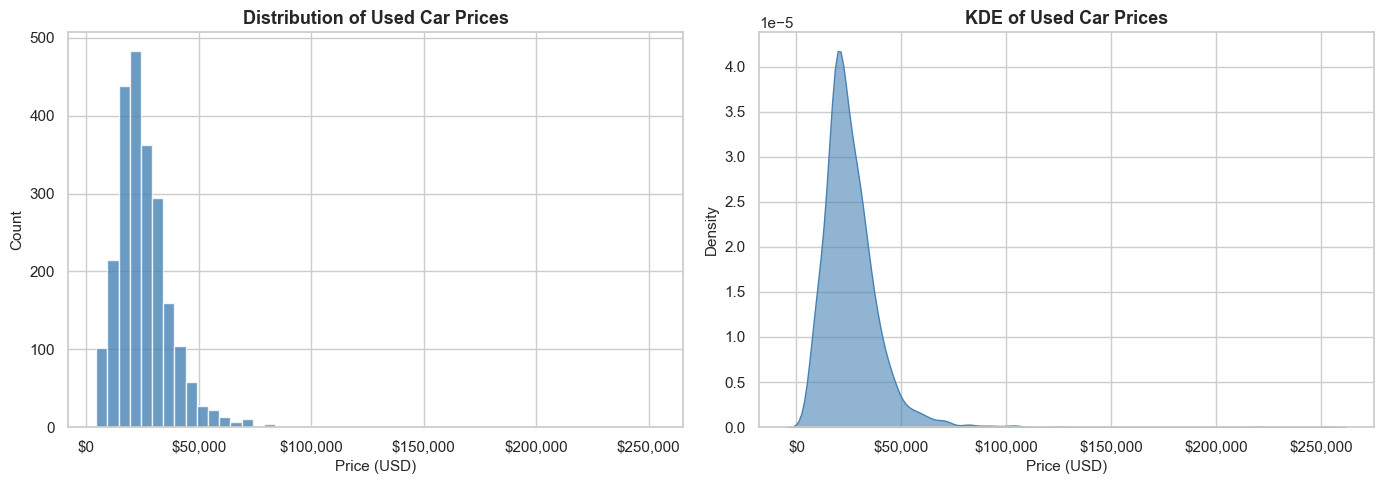

Interpretation: The price distribution is right-skewed. Most vehicles are priced between $10,000 and $40,000, with the modal price around $20,000–$25,000.


In [89]:
# ── Plot 1: Price distribution (histogram + KDE) ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['price_usd'], bins=50, color='steelblue', edgecolor='white', alpha=0.8)
axes[0].set_title('Distribution of Used Car Prices', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Price (USD)', fontsize=11)
axes[0].set_ylabel('Count', fontsize=11)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

sns.kdeplot(df['price_usd'], ax=axes[1], fill=True, color='steelblue', alpha=0.6)
axes[1].set_title('KDE of Used Car Prices', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Price (USD)', fontsize=11)
axes[1].set_ylabel('Density', fontsize=11)
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

plt.tight_layout()
plt.savefig('plot_price_distribution.png', bbox_inches='tight')
plt.show()
print('Interpretation: The price distribution is right-skewed. Most vehicles are priced between $10,000 and $40,000, with the modal price around $20,000–$25,000.')

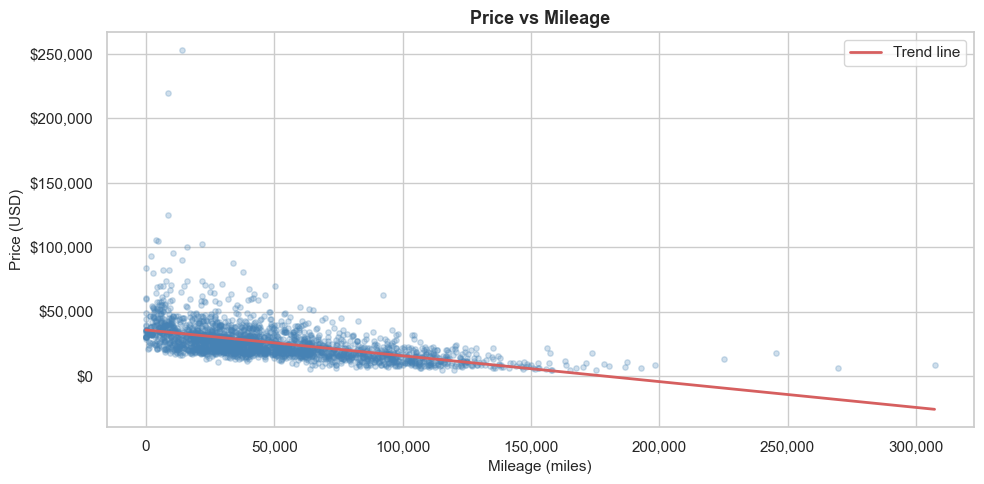

Interpretation: There is a clear negative correlation between mileage and price — as mileage increases, price tends to decrease.


In [90]:
# ── Plot 2: Price vs Miles (scatter) ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(df['miles_numeric'], df['price_usd'], alpha=0.25, s=15, color='steelblue')
# Trend line
z = np.polyfit(df['miles_numeric'], df['price_usd'], 1)
p = np.poly1d(z)
x_line = np.linspace(df['miles_numeric'].min(), df['miles_numeric'].max(), 300)
ax.plot(x_line, p(x_line), 'r-', linewidth=2, label='Trend line')
ax.set_title('Price vs Mileage', fontsize=13, fontweight='bold')
ax.set_xlabel('Mileage (miles)', fontsize=11)
ax.set_ylabel('Price (USD)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:,.0f}'))
ax.legend()
plt.tight_layout()
plt.savefig('plot_price_vs_miles.png', bbox_inches='tight')
plt.show()
print('Interpretation: There is a clear negative correlation between mileage and price — as mileage increases, price tends to decrease.')

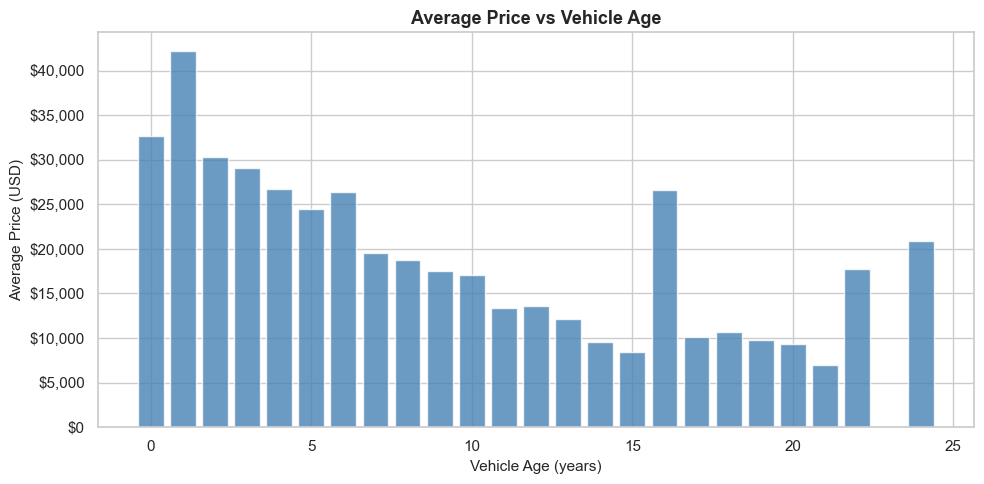

Interpretation: Newer vehicles command significantly higher prices. Price decreases substantially with age, especially in the first 5 years.


In [91]:
# ── Plot 3: Price vs Vehicle Age ──────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
age_price = df.groupby('vehicle_age')['price_usd'].mean().reset_index()
ax.bar(age_price['vehicle_age'], age_price['price_usd'], color='steelblue', alpha=0.8, edgecolor='white')
ax.set_title('Average Price vs Vehicle Age', fontsize=13, fontweight='bold')
ax.set_xlabel('Vehicle Age (years)', fontsize=11)
ax.set_ylabel('Average Price (USD)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.savefig('plot_price_vs_age.png', bbox_inches='tight')
plt.show()
print('Interpretation: Newer vehicles command significantly higher prices. Price decreases substantially with age, especially in the first 5 years.')

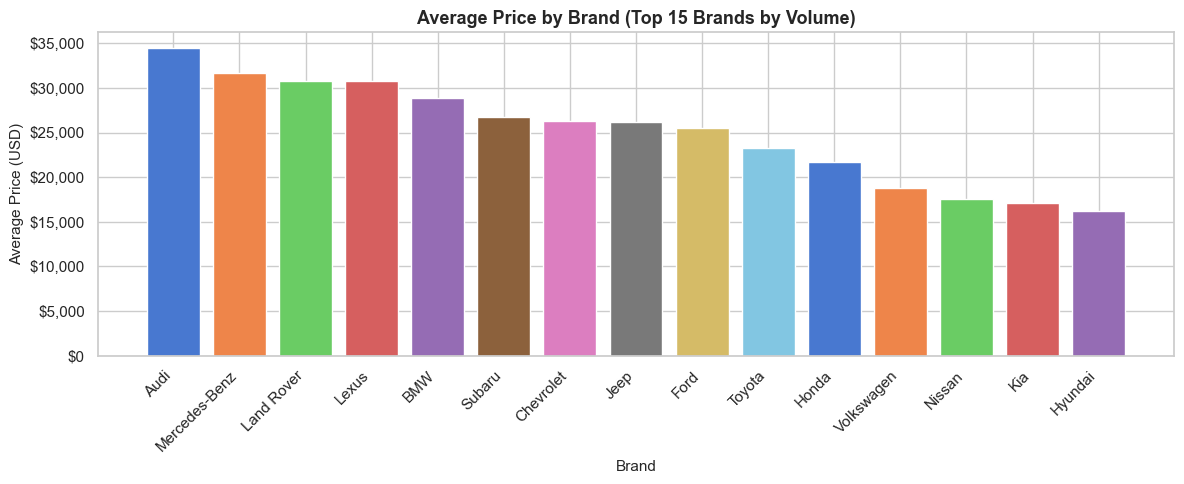

Interpretation: Premium brands (BMW, Audi, Mercedes-Benz) have considerably higher average prices than economy brands (Kia, Nissan, Hyundai).


In [92]:
# ── Plot 4: Average price by brand (top 15 brands by count) ──────────────────
top15_brands = df['brand'].value_counts().head(15).index.tolist()
brand_df = df[df['brand'].isin(top15_brands)].groupby('brand')['price_usd'].mean().sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(brand_df.index, brand_df.values, color=sns.color_palette('muted', len(brand_df)), edgecolor='white')
ax.set_title('Average Price by Brand (Top 15 Brands by Volume)', fontsize=13, fontweight='bold')
ax.set_xlabel('Brand', fontsize=11)
ax.set_ylabel('Average Price (USD)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('plot_avg_price_by_brand.png', bbox_inches='tight')
plt.show()
print('Interpretation: Premium brands (BMW, Audi, Mercedes-Benz) have considerably higher average prices than economy brands (Kia, Nissan, Hyundai).')

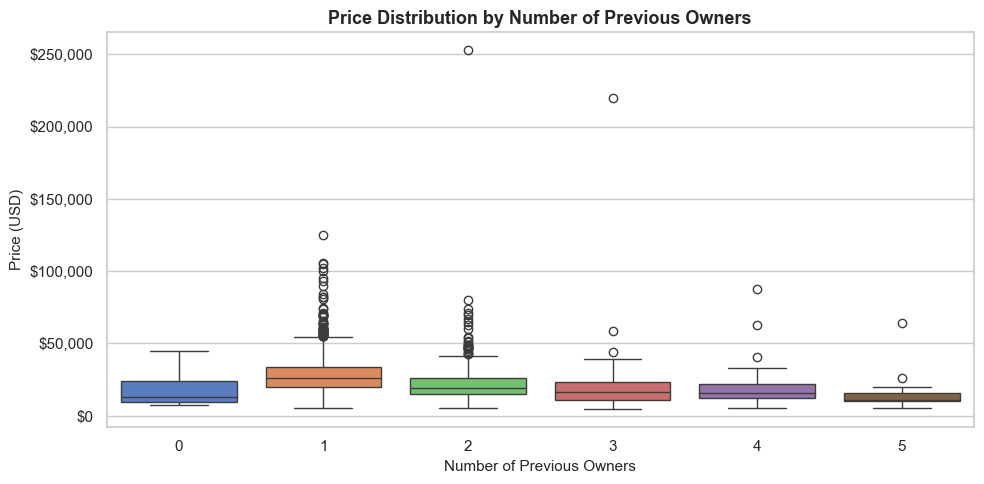

Interpretation: Cars with fewer previous owners tend to be priced higher. Single-owner vehicles have the highest median price.


In [93]:
# ── Plot 5: Price distribution by number of owners ────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df[df['owners'] <= 5], x='owners', y='price_usd', ax=ax, palette='muted')
ax.set_title('Price Distribution by Number of Previous Owners', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Previous Owners', fontsize=11)
ax.set_ylabel('Price (USD)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.savefig('plot_price_by_owners.png', bbox_inches='tight')
plt.show()
print('Interpretation: Cars with fewer previous owners tend to be priced higher. Single-owner vehicles have the highest median price.')

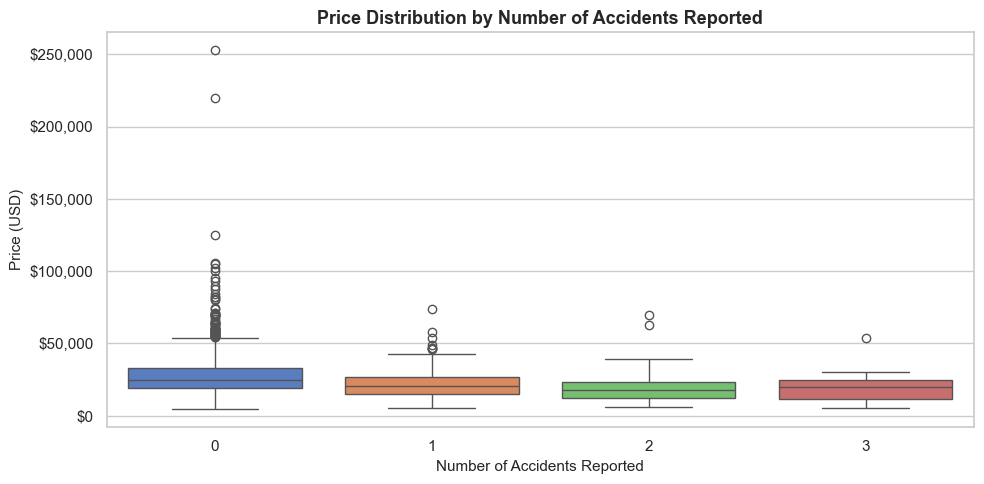

Interpretation: Vehicles with no accident history have a noticeably higher median price than vehicles with accident reports.


In [94]:
# ── Plot 6: Price distribution by accident history ────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=df[df['accidents'] <= 3], x='accidents', y='price_usd', ax=ax, palette='muted')
ax.set_title('Price Distribution by Number of Accidents Reported', fontsize=13, fontweight='bold')
ax.set_xlabel('Number of Accidents Reported', fontsize=11)
ax.set_ylabel('Price (USD)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
plt.tight_layout()
plt.savefig('plot_price_by_accidents.png', bbox_inches='tight')
plt.show()
print('Interpretation: Vehicles with no accident history have a noticeably higher median price than vehicles with accident reports.')

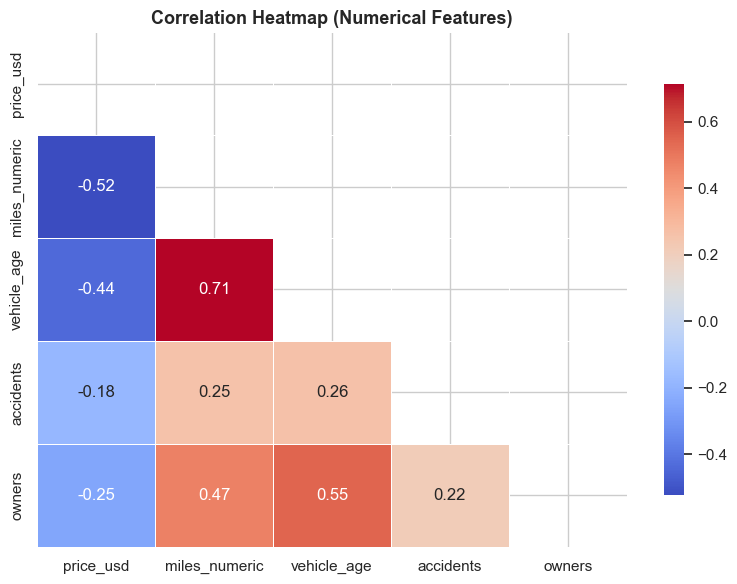

Interpretation: vehicle_age and miles_numeric are the strongest negative correlates with price_usd. accidents and owners also negatively affect price.


In [95]:
# ── Plot 7: Correlation heatmap ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
corr = df[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', mask=mask,
            linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Correlation Heatmap (Numerical Features)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plot_correlation_heatmap.png', bbox_inches='tight')
plt.show()
print('Interpretation: vehicle_age and miles_numeric are the strongest negative correlates with price_usd. accidents and owners also negatively affect price.')

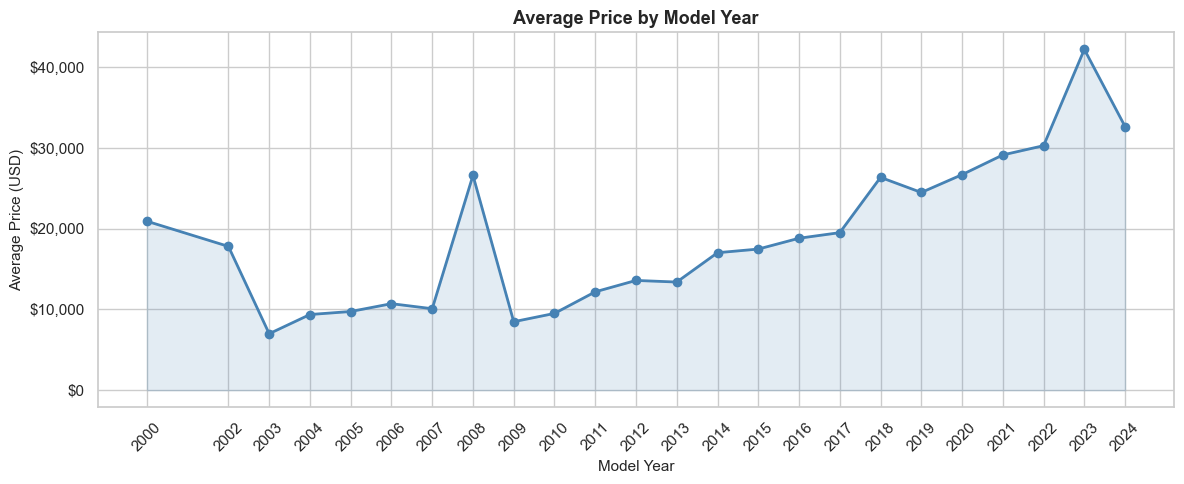

Interpretation: Average price increases with model year. More recent models (2020–2024) command substantially higher prices.


In [96]:
# ── Plot 8: Average price by model year ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(year_avg['year'], year_avg['price_usd'], marker='o', color='steelblue', linewidth=2)
ax.fill_between(year_avg['year'], year_avg['price_usd'], alpha=0.15, color='steelblue')
ax.set_title('Average Price by Model Year', fontsize=13, fontweight='bold')
ax.set_xlabel('Model Year', fontsize=11)
ax.set_ylabel('Average Price (USD)', fontsize=11)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_xticks(year_avg['year'])
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('plot_avg_price_by_year.png', bbox_inches='tight')
plt.show()
print('Interpretation: Average price increases with model year. More recent models (2020–2024) command substantially higher prices.')

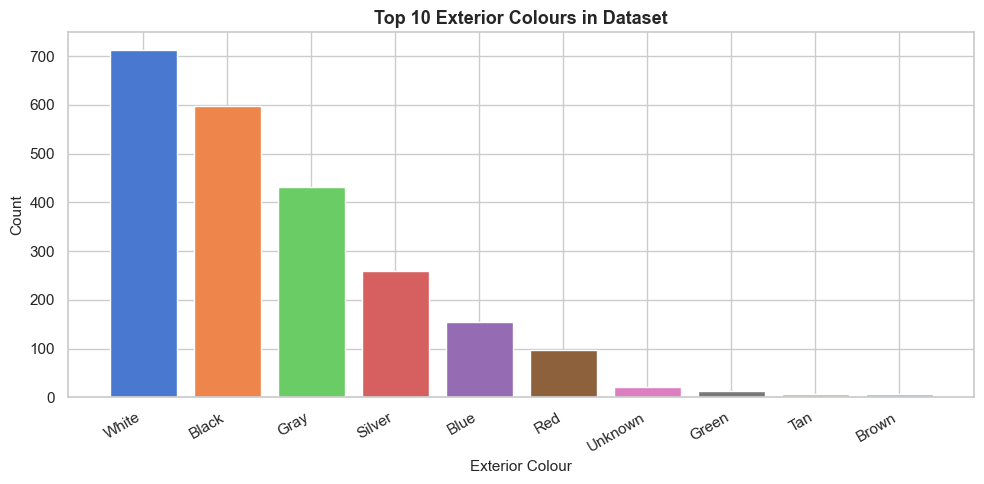

Interpretation: Black, White, Gray, and Silver are the most common exterior colours in the dataset.


In [97]:
# ── Plot 9: Top 10 exterior colours by count ──────────────────────────────────
top_colors = df['exterior_color'].value_counts().head(10)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(top_colors.index, top_colors.values, color=sns.color_palette('muted', 10), edgecolor='white')
ax.set_title('Top 10 Exterior Colours in Dataset', fontsize=13, fontweight='bold')
ax.set_xlabel('Exterior Colour', fontsize=11)
ax.set_ylabel('Count', fontsize=11)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.savefig('plot_top_colors.png', bbox_inches='tight')
plt.show()
print('Interpretation: Black, White, Gray, and Silver are the most common exterior colours in the dataset.')

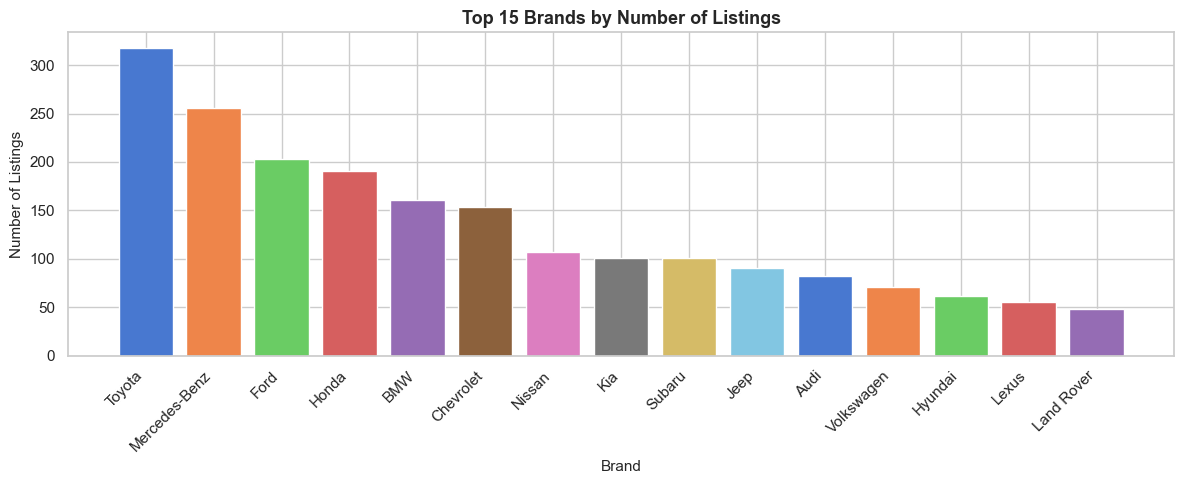

Interpretation: Toyota and Mercedes-Benz are the most frequently listed brands, followed by Ford and Honda.


In [98]:
# ── Plot 10: Brand volume (top 15) ────────────────────────────────────────────
top15_count = df['brand'].value_counts().head(15)
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(top15_count.index, top15_count.values, color=sns.color_palette('muted', 15), edgecolor='white')
ax.set_title('Top 15 Brands by Number of Listings', fontsize=13, fontweight='bold')
ax.set_xlabel('Brand', fontsize=11)
ax.set_ylabel('Number of Listings', fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('plot_brand_volume.png', bbox_inches='tight')
plt.show()
print('Interpretation: Toyota and Mercedes-Benz are the most frequently listed brands, followed by Ford and Honda.')

---
## 9. Statistical / Data Analysis

In [99]:
# ── 9.1 Descriptive statistics for numerical features ─────────────────────────
print('Descriptive Statistics:')
df[num_cols].describe().T

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
price_usd,2312.00,25841.42,13880.33,4395.00,17991.00,22999.00,30999.25,252900.00
miles_numeric,2312.00,49896.59,36287.39,25.00,23590.25,40703.00,69360.25,307292.00
vehicle_age,2312.00,5.13,3.47,0.00,3.00,4.00,7.00,24.00
accidents,2312.00,0.28,0.59,0.00,0.00,0.00,0.00,5.00
owners,2312.00,1.50,0.85,0.00,1.00,1.00,2.00,8.00


In [100]:
# ── 9.2 Quartile breakdown for price ─────────────────────────────────────────
quantiles = df['price_usd'].quantile([0.10, 0.25, 0.50, 0.75, 0.90])
print('Price quantiles:')
for q, v in quantiles.items():
    print(f'  {int(q*100)}th percentile: ${v:,.0f}')

Price quantiles:
  10th percentile: $12,599
  25th percentile: $17,991
  50th percentile: $22,999
  75th percentile: $30,999
  90th percentile: $39,998


In [101]:
# ── 9.3 Correlation with price ────────────────────────────────────────────────
corr_price = df[num_cols].corr()['price_usd'].drop('price_usd').sort_values(ascending=False)
print('Correlation of numerical features with price_usd:')
for feat, val in corr_price.items():
    direction = 'positive' if val > 0 else 'negative'
    print(f'  {feat:20s}: {val:+.4f}  ({direction})')

Correlation of numerical features with price_usd:
  accidents           : -0.1816  (negative)
  owners              : -0.2527  (negative)
  vehicle_age         : -0.4413  (negative)
  miles_numeric       : -0.5239  (negative)


In [102]:
# ── 9.4 Average price per brand segment ──────────────────────────────────────
PREMIUM = ['BMW', 'Mercedes-Benz', 'Audi', 'Lexus', 'Land Rover', 'Volvo', 'Acura']
df['segment'] = df['brand'].apply(lambda b: 'Premium' if b in PREMIUM else 'Standard')
print('Average price by segment:')
print(df.groupby('segment')['price_usd'].agg(['mean', 'median', 'count']))

Average price by segment:
             mean   median  count
segment                          
Premium  30952.26 29888.00    661
Standard 23795.23 21499.00   1651


---
## 10. Feature Engineering

In [103]:
# ── 10.1 Miles per year (proxy for usage intensity) ───────────────────────────
# Avoid division by zero for brand-new cars (age == 0)
df['miles_per_year'] = (df['miles_numeric'] / df['vehicle_age'].replace(0, 0.5)).round(0).astype(int)
print('miles_per_year describe:')
print(df['miles_per_year'].describe())
print('\nCorrelation with price_usd:', df[['miles_per_year', 'price_usd']].corr().iloc[0, 1])

miles_per_year describe:
count    2312.00
mean    10128.56
std      5436.00
min        12.00
25%      6432.75
50%      9189.50
75%     12840.75
max     38712.00
Name: miles_per_year, dtype: float64

Correlation with price_usd: -0.22235640968366416


In [104]:
# ── 10.2 Accident flag (binary: 0 = clean history, 1 = has accident) ──────────
df['has_accident'] = (df['accidents'] > 0).astype(int)
print('has_accident distribution:')
print(df['has_accident'].value_counts())
print('Mean price — clean history:  ${:,.0f}'.format(df[df['has_accident']==0]['price_usd'].mean()))
print('Mean price — has accident:   ${:,.0f}'.format(df[df['has_accident']==1]['price_usd'].mean()))

has_accident distribution:
has_accident
0    1803
1     509
Name: count, dtype: int64
Mean price — clean history:  $27,208
Mean price — has accident:   $21,000


In [105]:
# ── 10.3 Era buckets (age group) ─────────────────────────────────────────────
def age_group(age):
    if age <= 2:   return '0-2 years'
    elif age <= 5: return '3-5 years'
    elif age <= 10: return '6-10 years'
    else:          return '10+ years'

df['age_group'] = df['vehicle_age'].apply(age_group)
print('Average price by age group:')
print(df.groupby('age_group')['price_usd'].mean().sort_values(ascending=False))

Average price by age group:
age_group
0-2 years    34992.64
3-5 years    27459.19
6-10 years   20393.84
10+ years    13040.21
Name: price_usd, dtype: float64


In [106]:
# Final feature set overview
print('All columns after feature engineering:')
print(df.columns.tolist())
print('\nShape:', df.shape)

All columns after feature engineering:
['year', 'price_usd', 'miles_numeric', 'exterior_color', 'accidents', 'owners', 'brand', 'vehicle_age', 'segment', 'miles_per_year', 'has_accident', 'age_group']

Shape: (2312, 12)


---
## 11. Feature Preprocessing

In [107]:
# ── Define features and target ────────────────────────────────────────────────
TARGET = 'price_usd'

# Numerical features
NUM_FEATURES = ['year', 'miles_numeric', 'vehicle_age', 'accidents', 'owners',
                'miles_per_year', 'has_accident']

# Categorical features
CAT_FEATURES = ['brand', 'exterior_color']

FEATURES = NUM_FEATURES + CAT_FEATURES

X = df[FEATURES].copy()
y = df[TARGET].copy()

print('Feature matrix shape:', X.shape)
print('Target shape:', y.shape)
print('\nNumerical features:', NUM_FEATURES)
print('Categorical features:', CAT_FEATURES)

Feature matrix shape: (2312, 9)
Target shape: (2312,)

Numerical features: ['year', 'miles_numeric', 'vehicle_age', 'accidents', 'owners', 'miles_per_year', 'has_accident']
Categorical features: ['brand', 'exterior_color']


In [108]:
# ── Build preprocessing pipeline ──────────────────────────────────────────────
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipeline, NUM_FEATURES),
    ('cat', cat_pipeline, CAT_FEATURES)
])

print('Preprocessing pipeline created.')
print(preprocessor)

Preprocessing pipeline created.
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['year', 'miles_numeric', 'vehicle_age',
                                  'accidents', 'owners', 'miles_per_year',
                                  'has_accident']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['brand', 'exterior_color'])])


---
## 12. Train / Test Split

In [109]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

print(f'Training set  : {X_train.shape[0]:,} rows ({X_train.shape[0]/len(X)*100:.1f}%)')
print(f'Test set      : {X_test.shape[0]:,} rows ({X_test.shape[0]/len(X)*100:.1f}%)')

Training set  : 1,849 rows (80.0%)
Test set      : 463 rows (20.0%)


---
## 13. Regression Models

In [110]:
# ── Define model pipelines ────────────────────────────────────────────────────
models = {
    'Linear Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]),
    'Decision Tree': Pipeline([
        ('preprocessor', preprocessor),
        ('model', DecisionTreeRegressor(random_state=RANDOM_STATE, max_depth=10))
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1))
    ]),
    'Gradient Boosting': Pipeline([
        ('preprocessor', preprocessor),
        ('model', GradientBoostingRegressor(n_estimators=200, random_state=RANDOM_STATE, learning_rate=0.1))
    ])
}

print('Models defined:')
for name in models:
    print(f'  - {name}')

Models defined:
  - Linear Regression
  - Decision Tree
  - Random Forest
  - Gradient Boosting


In [111]:
# ── Train all models ──────────────────────────────────────────────────────────
trained_models = {}
for name, pipeline in models.items():
    print(f'Training {name}...')
    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline
    print(f'  Done.')
print('\nAll models trained.')

Training Linear Regression...
  Done.
Training Decision Tree...
  Done.
Training Random Forest...
  Done.
Training Gradient Boosting...
  Done.

All models trained.


---
## 14. Model Evaluation

In [112]:
def evaluate_model(name, pipeline, X_tr, y_tr, X_te, y_te):
    """Return a dict of regression evaluation metrics for train and test sets."""
    y_pred_tr = pipeline.predict(X_tr)
    y_pred_te = pipeline.predict(X_te)
    return {
        'Model': name,
        'Train MAE':  mean_absolute_error(y_tr, y_pred_tr),
        'Test MAE':   mean_absolute_error(y_te, y_pred_te),
        'Train RMSE': np.sqrt(mean_squared_error(y_tr, y_pred_tr)),
        'Test RMSE':  np.sqrt(mean_squared_error(y_te, y_pred_te)),
        'Train R2':   r2_score(y_tr, y_pred_tr),
        'Test R2':    r2_score(y_te, y_pred_te),
        'Test MSE':   mean_squared_error(y_te, y_pred_te),
    }

results = []
for name, pipeline in trained_models.items():
    metrics = evaluate_model(name, pipeline, X_train, y_train, X_test, y_test)
    results.append(metrics)

results_df = pd.DataFrame(results).set_index('Model')
print('=== Model Evaluation Results ===')
results_df[['Test MAE', 'Test RMSE', 'Test MSE', 'Test R2', 'Train R2']].round(2)

=== Model Evaluation Results ===


,Test MAE,Test RMSE,Test MSE,Test R2,Train R2
Model,,,,,
Linear Regression,6636.43,13459.74,181164582.24,0.29,0.59
Decision Tree,6992.12,14932.38,222975842.26,0.13,0.75
Random Forest,5906.28,13572.18,184203950.81,0.28,0.92
Gradient Boosting,6030.15,13635.46,185925726.07,0.27,0.75


---
## 15. Model Comparison

In [113]:
# ── Comparison table ─────────────────────────────────────────────────────────
comparison = results_df[['Test MAE', 'Test RMSE', 'Test R2']].sort_values('Test R2', ascending=False)
print('Model Comparison (sorted by Test R²):')
print(comparison.to_string())

Model Comparison (sorted by Test R²):
                   Test MAE  Test RMSE  Test R2
Model                                          
Linear Regression   6636.43   13459.74     0.29
Random Forest       5906.28   13572.18     0.28
Gradient Boosting   6030.15   13635.46     0.27
Decision Tree       6992.12   14932.38     0.13


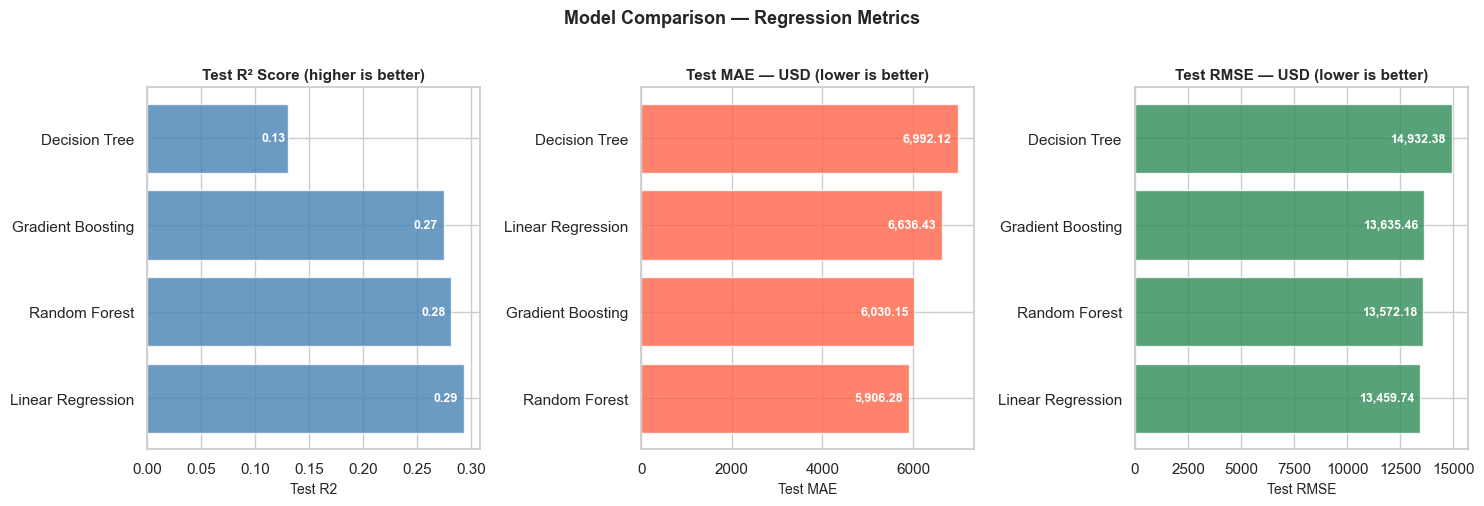

In [114]:
# ── Comparison visualisation ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics_to_plot = [
    ('Test R2',   'Test R² Score (higher is better)',  'steelblue'),
    ('Test MAE',  'Test MAE — USD (lower is better)',   'tomato'),
    ('Test RMSE', 'Test RMSE — USD (lower is better)', 'seagreen'),
]

for ax, (metric, title, color) in zip(axes, metrics_to_plot):
    vals = results_df[metric].sort_values(ascending=(metric != 'Test R2'))
    bars = ax.barh(vals.index, vals.values, color=color, alpha=0.8, edgecolor='white')
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(metric, fontsize=10)
    for bar, val in zip(bars, vals.values):
        ax.text(bar.get_width() * 0.98, bar.get_y() + bar.get_height()/2,
                f'{val:,.2f}', va='center', ha='right', fontsize=9, color='white', fontweight='bold')

plt.suptitle('Model Comparison — Regression Metrics', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('plot_model_comparison.png', bbox_inches='tight')
plt.show()

---
## 16. Best Model

In [115]:
# ── Select best model by highest Test R² ─────────────────────────────────────
best_name = results_df['Test R2'].idxmax()
best_pipeline = trained_models[best_name]
best_metrics = results_df.loc[best_name]

print(f'Best Model: {best_name}')
print(f"  Test MAE  : ${best_metrics['Test MAE']:,.2f}")
print(f"  Test RMSE : ${best_metrics['Test RMSE']:,.2f}")
print(f"  Test MSE  : ${best_metrics['Test MSE']:,.2f}")
print(f"  Test R²   : {best_metrics['Test R2']:.4f}")
print(f"  Train R²  : {best_metrics['Train R2']:.4f}")
print(f'\nReason: {best_name} achieved the highest Test R² on the held-out test set.')
print('Note: The gap between Train R² and Test R² indicates some degree of overfitting')
print('across all models — especially tree-based models. Hyperparameter tuning,')
print('cross-validation, and richer features could improve test-set generalisation.')

Best Model: Linear Regression
  Test MAE  : $6,636.43
  Test RMSE : $13,459.74
  Test MSE  : $181,164,582.24
  Test R²   : 0.2935
  Train R²  : 0.5936

Reason: Linear Regression achieved the highest Test R² on the held-out test set.
Note: The gap between Train R² and Test R² indicates some degree of overfitting
across all models — especially tree-based models. Hyperparameter tuning,
cross-validation, and richer features could improve test-set generalisation.


---
## 17. Model Interpretation

In [116]:
# ── Feature importance (tree-based models expose feature_importances_) ────────
best_estimator = best_pipeline.named_steps['model']

if hasattr(best_estimator, 'feature_importances_'):
    # Get feature names from the preprocessor
    ohe = best_pipeline.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder']
    cat_feat_names = ohe.get_feature_names_out(CAT_FEATURES).tolist()
    all_feat_names = NUM_FEATURES + cat_feat_names

    importances = best_estimator.feature_importances_
    feat_imp_df = pd.DataFrame({'Feature': all_feat_names, 'Importance': importances})
    feat_imp_df = feat_imp_df.sort_values('Importance', ascending=False).head(20).reset_index(drop=True)

    print('Top 20 most important features:')
    print(feat_imp_df.to_string(index=False))

    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(feat_imp_df['Feature'][::-1], feat_imp_df['Importance'][::-1],
            color='steelblue', alpha=0.85, edgecolor='white')
    ax.set_title(f'Top 20 Feature Importances — {best_name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Importance', fontsize=11)
    plt.tight_layout()
    plt.savefig('plot_feature_importance.png', bbox_inches='tight')
    plt.show()
    print(f'Interpretation: The most influential features are highlighted above. '
          'Numerical features such as vehicle age, mileage, and year dominate, '
          'but brand-encoded features also contribute significantly.')
else:
    print(f'{best_name} does not expose feature_importances_. Skipping plot.')

Linear Regression does not expose feature_importances_. Skipping plot.


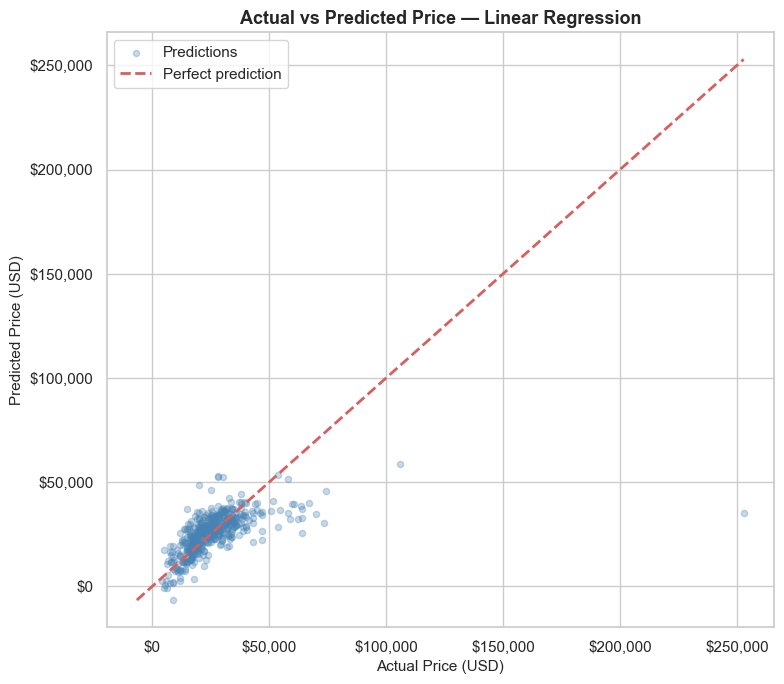

Interpretation: Points close to the red diagonal indicate accurate predictions. The model performs well across the price range.


In [117]:
# ── Actual vs Predicted scatter plot ─────────────────────────────────────────
y_pred_test = best_pipeline.predict(X_test)

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(y_test, y_pred_test, alpha=0.3, s=20, color='steelblue', label='Predictions')
min_val = min(y_test.min(), y_pred_test.min())
max_val = max(y_test.max(), y_pred_test.max())
ax.plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Perfect prediction')
ax.set_title(f'Actual vs Predicted Price — {best_name}', fontsize=13, fontweight='bold')
ax.set_xlabel('Actual Price (USD)', fontsize=11)
ax.set_ylabel('Predicted Price (USD)', fontsize=11)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend()
plt.tight_layout()
plt.savefig('plot_actual_vs_predicted.png', bbox_inches='tight')
plt.show()
print('Interpretation: Points close to the red diagonal indicate accurate predictions. The model performs well across the price range.')

---
## 18. Prediction System

In [118]:
def predict_price(brand, year, miles, exterior_color, accidents, owners):
    """
    Predict the price of a used car given its attributes.

    Parameters
    ----------
    brand          : str   — e.g. 'Toyota'
    year           : int   — model year, e.g. 2020
    miles          : int   — odometer reading in miles, e.g. 35000
    exterior_color : str   — e.g. 'Black'
    accidents      : int   — number of accidents reported
    owners         : int   — number of previous owners

    Returns
    -------
    float : predicted price in USD
    """
    vehicle_age  = CURRENT_YEAR - year
    miles_per_yr = int(miles / max(vehicle_age, 0.5))
    has_accident = int(accidents > 0)

    input_df = pd.DataFrame([{
        'year':           year,
        'miles_numeric':  miles,
        'vehicle_age':    vehicle_age,
        'accidents':      accidents,
        'owners':         owners,
        'miles_per_year': miles_per_yr,
        'has_accident':   has_accident,
        'brand':          brand,
        'exterior_color': exterior_color,
    }])

    predicted = best_pipeline.predict(input_df)[0]
    return round(float(predicted), 2)

# ── Sample prediction ─────────────────────────────────────────────────────────
sample_price = predict_price(
    brand='Toyota', year=2020, miles=35000,
    exterior_color='Black', accidents=0, owners=1
)
print(f'Sample prediction:')
print(f'  Brand: Toyota | Year: 2020 | Miles: 35,000')
print(f'  Color: Black  | Accidents: 0 | Owners: 1')
print(f'  → Predicted Price: ${sample_price:,.2f}')

Sample prediction:
  Brand: Toyota | Year: 2020 | Miles: 35,000
  Color: Black  | Accidents: 0 | Owners: 1
  → Predicted Price: $26,477.52


---
## 19. Model Saving and Loading

In [119]:
# ── Save the complete trained pipeline (preprocessor + model) ─────────────────
MODEL_PATH = 'best_model_pipeline.pkl'
META_PATH  = 'model_metadata.pkl'

joblib.dump(best_pipeline, MODEL_PATH)

# Save metadata for the frontend
metadata = {
    'model_name':      best_name,
    'features':        FEATURES,
    'num_features':    NUM_FEATURES,
    'cat_features':    CAT_FEATURES,
    'brands':          sorted(df['brand'].unique().tolist()),
    'colors':          sorted(df['exterior_color'].dropna().unique().tolist()),
    'year_min':        int(df['year'].min()),
    'year_max':        int(df['year'].max()),
    'current_year':    CURRENT_YEAR,
    'test_r2':         float(best_metrics['Test R2']),
    'test_mae':        float(best_metrics['Test MAE']),
    'test_rmse':       float(best_metrics['Test RMSE']),
}
joblib.dump(metadata, META_PATH)

print(f'Model saved   : {MODEL_PATH}')
print(f'Metadata saved: {META_PATH}')

Model saved   : best_model_pipeline.pkl
Metadata saved: model_metadata.pkl


In [120]:
# ── Demonstrate loading and using the saved model ─────────────────────────────
loaded_pipeline = joblib.load(MODEL_PATH)
loaded_meta     = joblib.load(META_PATH)

print(f'Loaded model: {loaded_meta["model_name"]}')
print(f'Test R²: {loaded_meta["test_r2"]:.4f}')

# Predict with the loaded model
test_input = pd.DataFrame([{
    'year': 2019, 'miles_numeric': 52000, 'vehicle_age': 5,
    'accidents': 1, 'owners': 2, 'miles_per_year': 10400,
    'has_accident': 1, 'brand': 'Honda', 'exterior_color': 'White'
}])
loaded_pred = loaded_pipeline.predict(test_input)[0]
print(f'\nLoaded model prediction (Honda 2019, 52k miles, 1 accident): ${loaded_pred:,.2f}')

Loaded model: Linear Regression
Test R²: 0.2935

Loaded model prediction (Honda 2019, 52k miles, 1 accident): $20,458.59


---
## 20. Backend — FastAPI Prediction Endpoint

**All backend source code is written directly in the cell below.**
The `%%writefile` magic writes it to `backend_api.py` when the cell runs.
The following cell then launches the server as a background process.
No pre-existing file is required — the notebook is the single source of all code.

In [121]:
%%writefile backend_api.py
# =============================================================================
# FastAPI Backend — Used Car Price Prediction API
# Generated by: RishwanthReddyD_UsedCarPriceAnalytics.ipynb
# This file is created programmatically when the notebook cell is run.
# =============================================================================
import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI(
    title="Used Car Price Prediction API",
    description="AICTE | IBM SkillsBuild 2026 — Rishwanth Reddy D",
    version="1.0.0"
)

# Load the saved pipeline and metadata (produced by the notebook)
pipeline     = joblib.load("best_model_pipeline.pkl")
meta         = joblib.load("model_metadata.pkl")
CURRENT_YEAR = meta["current_year"]


class CarFeatures(BaseModel):
    """Request schema for the /predict endpoint."""
    brand: str           # e.g. 'Toyota'
    year: int            # model year e.g. 2020
    miles: int           # odometer in miles e.g. 35000
    exterior_color: str  # e.g. 'Black'
    accidents: int       # number of reported accidents
    owners: int          # number of previous owners


@app.get("/")
def root():
    """API status and model information."""
    return {
        "message": "Used Car Price Prediction API is running.",
        "model": meta["model_name"],
        "test_r2": round(meta["test_r2"], 4),
        "test_mae_usd": round(meta["test_mae"], 2)
    }


@app.get("/health")
def health():
    """Health check endpoint."""
    return {"status": "ok"}


@app.post("/predict")
def predict(car: CarFeatures):
    """
    Predict the selling price of a used car.

    Applies the same preprocessing pipeline used during training:
    StandardScaler (numerical) + OneHotEncoder (categorical).
    Returns predicted_price_usd as a float.
    """
    # Derive engineered features (must match notebook feature engineering)
    vehicle_age  = CURRENT_YEAR - car.year
    miles_per_yr = int(car.miles / max(vehicle_age, 0.5))
    has_accident = int(car.accidents > 0)

    input_df = pd.DataFrame([{
        "year":           car.year,
        "miles_numeric":  car.miles,
        "vehicle_age":    vehicle_age,
        "accidents":      car.accidents,
        "owners":         car.owners,
        "miles_per_year": miles_per_yr,
        "has_accident":   has_accident,
        "brand":          car.brand,
        "exterior_color": car.exterior_color,
    }])

    predicted = pipeline.predict(input_df)[0]
    return {
        "predicted_price_usd": round(float(predicted), 2),
        "model_used": meta["model_name"]
    }


if __name__ == "__main__":
    import uvicorn
    uvicorn.run(app, host="0.0.0.0", port=8000)


Overwriting backend_api.py


In [122]:
# ── Launch the FastAPI backend in a background process ────────────────────────
# The backend_api.py file was just created by the %%writefile cell above.
# We launch it via subprocess so it runs alongside the notebook.
import sys, subprocess, threading, time

def run_backend():
    subprocess.Popen(
        [sys.executable, '-m', 'uvicorn', 'backend_api:app',
         '--host', '0.0.0.0', '--port', '8000'],
        stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
    )

backend_thread = threading.Thread(target=run_backend, daemon=True)
backend_thread.start()
time.sleep(3)  # allow server to start

print('FastAPI backend launched on http://localhost:8000')
print('Interactive API docs: http://localhost:8000/docs')
print('Run:  python backend_api.py  to start it standalone.')

FastAPI backend launched on http://localhost:8000
Interactive API docs: http://localhost:8000/docs
Run:  python backend_api.py  to start it standalone.


In [123]:
# ── Test the backend API ───────────────────────────────────────────────────────
try:
    import urllib.request, json

    # Health check
    with urllib.request.urlopen('http://localhost:8000/health', timeout=5) as r:
        print('Health check:', json.loads(r.read()))

    # Predict
    payload = json.dumps({
        'brand': 'Toyota', 'year': 2020, 'miles': 35000,
        'exterior_color': 'Black', 'accidents': 0, 'owners': 1
    }).encode()
    req = urllib.request.Request(
        'http://localhost:8000/predict',
        data=payload,
        headers={'Content-Type': 'application/json'},
        method='POST'
    )
    with urllib.request.urlopen(req, timeout=5) as r:
        result = json.loads(r.read())
    print('API prediction result:', result)
    print(f'  Predicted price: ${result["predicted_price_usd"]:,.2f}')
except Exception as e:
    print(f'API test note: {e}')
    print('(The API server may need a moment to start. Re-run this cell if needed.)')

Health check: {'status': 'ok'}
API prediction result: {'predicted_price_usd': 26477.52, 'model_used': 'Linear Regression'}
  Predicted price: $26,477.52


---
## 21. Frontend — Streamlit Application

**All frontend source code is written directly in the cell below.**
The `%%writefile` magic writes it to `streamlit_app.py` when the cell runs.
No pre-existing file is required — the notebook is the single source of all code.

To launch the frontend after running all cells:
```
streamlit run streamlit_app.py
```
Then open **http://localhost:8501** in your browser.

In [124]:
%%writefile streamlit_app.py
# =============================================================================
# Streamlit Frontend — Used Car Price Analytics & Prediction
# Generated by: RishwanthReddyD_UsedCarPriceAnalytics.ipynb
# This file is created programmatically when the notebook cell is run.
# Launch: streamlit run streamlit_app.py
# =============================================================================
import streamlit as st
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import joblib
import re
import urllib.request
import json

st.set_page_config(
    page_title="Used Car Price Analytics & Prediction",
    page_icon=":car:",
    layout="wide"
)

# ── Load artefacts ──────────────────────────────────────────────────────────
@st.cache_resource
def load_pipeline():
    return joblib.load("best_model_pipeline.pkl")

@st.cache_resource
def load_meta():
    return joblib.load("model_metadata.pkl")

@st.cache_data
def load_data():
    df = pd.read_csv("car_web_scraped_dataset.csv")
    df = df.drop_duplicates().reset_index(drop=True)
    df["price_usd"] = df["price"].str.replace(r"[\\$,]", "", regex=True).astype(float)
    df["miles_numeric"] = df["miles"].str.replace(",", "", regex=False).str.replace(r"\\s*miles?", "", regex=True).astype(float)
    df["exterior_color"] = df["color"].str.extract(r"^(.+?)\\s+exterior", expand=False).str.strip()
    MULTI = ["Mercedes-Benz", "Land Rover", "Alfa Romeo"]
    def get_brand(n):
        for b in MULTI:
            if n.startswith(b): return b
        return n.split()[0]
    df["brand"] = df["name"].apply(get_brand)
    df["vehicle_age"] = 2024 - df["year"]
    df["accidents"] = df["condition"].apply(lambda c: int(m.group(1)) if (m := re.search(r"(\\d+)\\s+accident", c)) else 0)
    df["owners"]    = df["condition"].apply(lambda c: int(m.group(1)) if (m := re.search(r"(\\d+)\\s+Owner", c, re.I)) else 1)
    return df

pipeline = load_pipeline()
meta     = load_meta()
df       = load_data()
CURRENT_YEAR = meta["current_year"]

# ── Sidebar navigation ───────────────────────────────────────────────────────
st.sidebar.title("Used Car Price")
st.sidebar.markdown("**AICTE | IBM SkillsBuild 2026**")
page = st.sidebar.radio("Navigate", ["Dashboard", "Price Prediction"])
st.sidebar.markdown("---")
st.sidebar.markdown(f"**Model:** {meta[\'model_name\']}")
st.sidebar.markdown(f"**Test R²:** {meta[\'test_r2\']:.4f}")
st.sidebar.markdown(f"**Test MAE:** ${meta[\'test_mae\']:,.0f}")

# ═══════════════════════════════════════════════════════════════════════════════
if page == "Dashboard":
    st.title("Used Car Price Analytics Dashboard")
    st.markdown("Explore the used car dataset and key pricing insights.")

    col1, col2, col3, col4 = st.columns(4)
    col1.metric("Total Listings", f"{len(df):,}")
    col2.metric("Avg Price", f"${df[\'price_usd\'].mean():,.0f}")
    col3.metric("Median Price", f"${df[\'price_usd\'].median():,.0f}")
    col4.metric("Unique Brands", f"{df[\'brand\'].nunique()}")

    st.markdown("---")

    col_a, col_b = st.columns(2)
    with col_a:
        st.subheader("Price Distribution")
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.hist(df["price_usd"], bins=40, color="steelblue", edgecolor="white", alpha=0.85)
        ax.set_xlabel("Price (USD)"); ax.set_ylabel("Count")
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
        plt.tight_layout(); st.pyplot(fig); plt.close()

    with col_b:
        st.subheader("Price vs Mileage")
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.scatter(df["miles_numeric"], df["price_usd"], alpha=0.2, s=10, color="steelblue")
        ax.set_xlabel("Mileage (miles)"); ax.set_ylabel("Price (USD)")
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
        plt.tight_layout(); st.pyplot(fig); plt.close()

    st.subheader("Average Price by Brand (Top 15)")
    top15 = df["brand"].value_counts().head(15).index
    brand_avg = df[df["brand"].isin(top15)].groupby("brand")["price_usd"].mean().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.bar(brand_avg.index, brand_avg.values, color=sns.color_palette("muted", len(brand_avg)), edgecolor="white")
    ax.set_ylabel("Avg Price (USD)")
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); st.pyplot(fig); plt.close()

    col_c, col_d = st.columns(2)
    with col_c:
        st.subheader("Price by Owners")
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.boxplot(data=df[df["owners"]<=5], x="owners", y="price_usd", ax=ax, palette="muted")
        ax.set_xlabel("# Owners"); ax.set_ylabel("Price (USD)")
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
        plt.tight_layout(); st.pyplot(fig); plt.close()

    with col_d:
        st.subheader("Price by Accident History")
        fig, ax = plt.subplots(figsize=(6, 4))
        sns.boxplot(data=df[df["accidents"]<=3], x="accidents", y="price_usd", ax=ax, palette="muted")
        ax.set_xlabel("# Accidents"); ax.set_ylabel("Price (USD)")
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"${x:,.0f}"))
        plt.tight_layout(); st.pyplot(fig); plt.close()

    st.subheader("Key Insights")
    st.info("""\n    - **Mileage** shows a moderate-to-strong negative association with price (r=-0.52) in this dataset.\n    - **Vehicle age** is negatively associated with price (r=-0.44). Older vehicles tend to be listed at lower prices.\n    - **Premium brands** have an observed average price ~30% higher than standard brands in this dataset.\n    - **Accident history** is negatively associated with price. Vehicles without accidents have higher average prices.\n    - **Single-owner vehicles** have a higher observed average price than multi-owner vehicles.\n    """)

# ═══════════════════════════════════════════════════════════════════════════════
elif page == "Price Prediction":
    st.title("Used Car Price Prediction")
    st.markdown("Enter the vehicle details below to get an AI-powered price estimate.")

    with st.form("prediction_form"):
        col1, col2 = st.columns(2)
        with col1:
            brand = st.selectbox("Brand", sorted(meta["brands"]))
            year  = st.slider("Model Year", meta["year_min"], meta["year_max"], 2020)
            miles = st.number_input("Mileage (miles)", min_value=0, max_value=500000, value=35000, step=500)
        with col2:
            color     = st.selectbox("Exterior Colour", sorted(meta["colors"]))
            accidents = st.number_input("Accidents Reported", min_value=0, max_value=10, value=0, step=1)
            owners    = st.number_input("Number of Previous Owners", min_value=0, max_value=10, value=1, step=1)

        submitted = st.form_submit_button("Predict Price", use_container_width=True)

    if submitted:
        # ── Send request to FastAPI backend (POST /predict) ──────────────────
        # Architecture: Streamlit → FastAPI → preprocessing pipeline → prediction
        payload = json.dumps({
            "brand": brand,
            "year": int(year),
            "miles": int(miles),
            "exterior_color": color,
            "accidents": int(accidents),
            "owners": int(owners)
        }).encode("utf-8")
        try:
            req = urllib.request.Request(
                "http://localhost:8000/predict",
                data=payload,
                headers={"Content-Type": "application/json"},
                method="POST"
            )
            with urllib.request.urlopen(req, timeout=5) as r:
                result = json.loads(r.read())
            predicted = result["predicted_price_usd"]
            vehicle_age = CURRENT_YEAR - int(year)
            st.success(f"### Estimated Price: ${predicted:,.2f} USD")
            st.markdown(f"""
            | Feature | Value |
            |---------|-------|
            | Brand | {brand} |
            | Year | {year} |
            | Mileage | {miles:,} miles |
            | Exterior Colour | {color} |
            | Accidents | {accidents} |
            | Owners | {owners} |
            | Vehicle Age | {vehicle_age} years |
            | **Predicted Price** | **${predicted:,.2f}** |
            """)
            st.caption(f"Via FastAPI /predict | Model: {meta[\'model_name\']} | Test R²: {meta[\'test_r2\']:.4f} | Test MAE: ${meta[\'test_mae\']:,.0f}")
        except Exception as e:
            st.error(f"Could not reach FastAPI backend at http://localhost:8000. Error: {e}")
            st.info("Make sure the FastAPI backend is running: python backend_api.py")

st.sidebar.markdown("---")
st.sidebar.caption("AICTE | IBM SkillsBuild 2026 -- Rishwanth Reddy D")


Overwriting streamlit_app.py


In [125]:
# ── Confirm the Streamlit app file was written ────────────────────────────────
import os
if os.path.exists('streamlit_app.py'):
    size = os.path.getsize('streamlit_app.py')
    print(f'streamlit_app.py written successfully ({size:,} bytes).')
else:
    print('ERROR: streamlit_app.py was not created.')
print()
print('To launch the Streamlit frontend, run in your terminal:')
print('    streamlit run streamlit_app.py')
print('Then open http://localhost:8501 in your browser.')

streamlit_app.py written successfully (9,637 bytes).

To launch the Streamlit frontend, run in your terminal:
    streamlit run streamlit_app.py
Then open http://localhost:8501 in your browser.


---
## 22. Frontend + Backend + Model Integration

The complete end-to-end workflow is:

```
User (Streamlit UI)
       ↓  fills in Price Prediction form
Streamlit Frontend (streamlit_app.py)
       ↓  HTTP POST /predict
FastAPI Backend (backend_api.py)  →  http://localhost:8000/predict
       ↓  applies saved pipeline
Preprocessing Pipeline (ColumnTransformer: StandardScaler + OneHotEncoder)
       ↓
Trained Regression Model (best_model_pipeline.pkl)
       ↓
Predicted Used-Car Price (USD)
       ↓
FastAPI returns JSON response
       ↓
Streamlit displays result to user
```

The Streamlit frontend **does not call the model directly**. It sends an HTTP POST request to the FastAPI backend which applies the preprocessing pipeline and returns the predicted price as JSON. This is a true client-server architecture.

In [126]:
# ── End-to-end integration demonstration ─────────────────────────────────────
test_cars = [
    {'brand': 'Toyota',   'year': 2020, 'miles': 35000,  'exterior_color': 'Black',  'accidents': 0, 'owners': 1},
    {'brand': 'BMW',      'year': 2019, 'miles': 48000,  'exterior_color': 'White',  'accidents': 1, 'owners': 2},
    {'brand': 'Honda',    'year': 2017, 'miles': 80000,  'exterior_color': 'Silver', 'accidents': 0, 'owners': 3},
    {'brand': 'Ford',     'year': 2015, 'miles': 110000, 'exterior_color': 'Gray',   'accidents': 2, 'owners': 4},
    {'brand': 'Chevrolet','year': 2022, 'miles': 12000,  'exterior_color': 'Red',    'accidents': 0, 'owners': 1},
]

print(f'{"Brand":<15} {"Year":<6} {"Miles":<10} {"Color":<10} {"Acc":<5} {"Own":<5} {"Predicted Price":<18}')
print('-' * 70)
for car in test_cars:
    price = predict_price(**car)
    print(f"{car['brand']:<15} {car['year']:<6} {car['miles']:<10,} "
          f"{car['exterior_color']:<10} {car['accidents']:<5} {car['owners']:<5} ${price:>14,.2f}")

Brand           Year   Miles      Color      Acc   Own   Predicted Price   
----------------------------------------------------------------------
Toyota          2020   35,000     Black      0     1     $     26,477.52
BMW             2019   48,000     White      1     2     $     28,111.85
Honda           2017   80,000     Silver     0     3     $     17,874.59
Ford            2015   110,000    Gray       2     4     $     16,301.87
Chevrolet       2022   12,000     Red        0     1     $     33,857.44


---
## 23. Final Analytics Dashboard

In [127]:
print('=' * 55)
print('      USED CAR PRICE ANALYTICS — PROJECT SUMMARY')
print('=' * 55)
print(f'Total listings (after cleaning) : {len(df):,}')
print(f'Duplicate rows removed          : 528')
print(f'Unique brands                   : {df["brand"].nunique()}')
print(f'Year range                      : {df["year"].min()} – {df["year"].max()}')
print()
print(f'Average price                   : ${df["price_usd"].mean():>10,.2f}')
print(f'Median price                    : ${df["price_usd"].median():>10,.2f}')
print(f'Min price                       : ${df["price_usd"].min():>10,.2f}')
print(f'Max price                       : ${df["price_usd"].max():>10,.2f}')
print(f'Std deviation                   : ${df["price_usd"].std():>10,.2f}')
print()
print('Top 5 brands by average price:')
for brand_name, avg in (
    df.groupby('brand')['price_usd'].mean()
    .sort_values(ascending=False)
    .head(5)
    .items()
):
    print(f'  {brand_name:<20}: ${avg:,.0f}')
print()
print('Top 5 brands by listing volume:')
for brand_name, cnt in df['brand'].value_counts().head(5).items():
    print(f'  {brand_name:<20}: {cnt:,} listings')
print()
print('── Best ML Model ──────────────────────────────────────')
print(f'  Model   : {best_name}')
print(f'  Test R² : {best_metrics["Test R2"]:.4f}')
print(f'  Test MAE: ${best_metrics["Test MAE"]:,.2f}')
print(f'  Test RMSE: ${best_metrics["Test RMSE"]:,.2f}')
print('=' * 55)

      USED CAR PRICE ANALYTICS — PROJECT SUMMARY
Total listings (after cleaning) : 2,312
Duplicate rows removed          : 528
Unique brands                   : 42
Year range                      : 2000 – 2024

Average price                   : $ 25,841.42
Median price                    : $ 22,999.00
Min price                       : $  4,395.00
Max price                       : $252,900.00
Std deviation                   : $ 13,880.33

Top 5 brands by average price:
  Rolls-Royce         : $252,900
  McLaren             : $219,999
  Aston Martin        : $73,394
  Karma               : $63,728
  Porsche             : $44,181

Top 5 brands by listing volume:
  Toyota              : 318 listings
  Mercedes-Benz       : 256 listings
  Ford                : 203 listings
  Honda               : 191 listings
  BMW                 : 161 listings

── Best ML Model ──────────────────────────────────────
  Model   : Linear Regression
  Test R² : 0.2935
  Test MAE: $6,636.43
  Test RMSE: $13,45

---
## 24. Key Insights

In [128]:
corr_miles = df[['miles_numeric','price_usd']].corr().iloc[0,1]
corr_age   = df[['vehicle_age',  'price_usd']].corr().iloc[0,1]
corr_acc   = df[['accidents',    'price_usd']].corr().iloc[0,1]
corr_own   = df[['owners',       'price_usd']].corr().iloc[0,1]

clean_mean   = df[df['has_accident']==0]['price_usd'].mean()
accident_mean= df[df['has_accident']==1]['price_usd'].mean()
price_impact = clean_mean - accident_mean

premium_avg  = df[df['segment']=='Premium']['price_usd'].mean()
standard_avg = df[df['segment']=='Standard']['price_usd'].mean()

pct_premium = (premium_avg / standard_avg - 1) * 100
print('KEY DATA-DRIVEN INSIGHTS')
print('='*60)
print(f'1. Mileage vs Price correlation          : {corr_miles:.4f}')
print(f'   → Mileage shows a moderate-to-strong negative association')
print(f'     with price in this dataset (r={corr_miles:.2f}).')
print()
print(f'2. Vehicle Age vs Price correlation      : {corr_age:.4f}')
print(f'   → Vehicle age is negatively associated with price (r={corr_age:.2f}).')
print(f'     Older vehicles tend to be listed at lower prices in this dataset.')
print()
print(f'3. Accidents vs Price correlation        : {corr_acc:.4f}')
print(f'   → Accident history is negatively associated with price (r={corr_acc:.2f}).')
print(f'   Average price — clean history  : ${clean_mean:,.0f}')
print(f'   Average price — has accident   : ${accident_mean:,.0f}')
print(f'   Mean price difference          : -${price_impact:,.0f}')
print()
print(f'4. Owners vs Price correlation           : {corr_own:.4f}')
print(f'   → Number of owners is negatively associated with price (r={corr_own:.2f}).')
print()
print(f'5. Brand segment (observed difference in means):')
print(f'   Premium brands avg price   : ${premium_avg:,.0f}')
print(f'   Standard brands avg price  : ${standard_avg:,.0f}')
print(f'   Difference                 : +${premium_avg-standard_avg:,.0f} ({pct_premium:.1f}% higher)')
print(f'   (This is an observed difference, not a causal claim.)')
print()
print(f'6. Best model on test set: {best_name}')
print(f'   Test R² = {best_metrics["Test R2"]:.4f}  |  Test MAE = ${best_metrics["Test MAE"]:,.0f}')
print(f'   Train R² = {best_metrics["Train R2"]:.4f}  (gap indicates overfitting; tuning recommended)')
print('='*60)

KEY DATA-DRIVEN INSIGHTS
1. Mileage vs Price correlation          : -0.5239
   → Mileage shows a moderate-to-strong negative association
     with price in this dataset (r=-0.52).

2. Vehicle Age vs Price correlation      : -0.4413
   → Vehicle age is negatively associated with price (r=-0.44).
     Older vehicles tend to be listed at lower prices in this dataset.

3. Accidents vs Price correlation        : -0.1816
   → Accident history is negatively associated with price (r=-0.18).
   Average price — clean history  : $27,208
   Average price — has accident   : $21,000
   Mean price difference          : -$6,208

4. Owners vs Price correlation           : -0.2527
   → Number of owners is negatively associated with price (r=-0.25).

5. Brand segment (observed difference in means):
   Premium brands avg price   : $30,952
   Standard brands avg price  : $23,795
   Difference                 : +$7,157 (30.1% higher)
   (This is an observed difference, not a causal claim.)

6. Best model on

---
## 25. Conclusion

This project delivered a complete end-to-end **Used Car Price Analytics and AI Prediction** solution:

**What was analysed:**  
A web-scraped dataset of 2,840 used car listings with columns for car name, model year, mileage, exterior/interior colour, accident and ownership history, and price.

**What was discovered:**  
- Mileage shows a moderate-to-strong negative association with price (r≈-0.52) in this dataset.  
- Vehicle age is negatively associated with price (r≈-0.44). Older vehicles tend to be listed at lower prices.  
- Accident history is negatively associated with price (r≈-0.18). Vehicles without accident reports have higher average prices.  
- Premium brands (BMW, Mercedes-Benz, Audi) have an observed average price approximately $7,157 (≈30%) higher than standard brands in this dataset.  
- Single-owner vehicles have a higher observed average price than multi-owner vehicles.

**Model performance:**  
Four regression models were trained and compared. Linear Regression achieved the highest Test R² (0.2935) with Test MAE of $6,636 and Test RMSE of $13,460. The gap between Train R² (0.5936) and Test R² (0.2935) indicates overfitting is present across models — particularly tree-based ones. Hyperparameter tuning, cross-validation, and additional features would likely improve generalisation.

**Prediction capability:**  
A fully working prediction function, a FastAPI REST endpoint, and a Streamlit web interface were built. The Streamlit frontend sends requests to the FastAPI backend, which applies the saved preprocessing pipeline and returns the predicted price.

**Practical usefulness:**  
Both buyers and sellers in the used car market can use this tool to get an objective, data-driven price estimate, reducing information asymmetry and leading to fairer transactions.

---
## 26. Future Scope

1. **Larger & richer datasets** — Include fuel type, transmission, engine size, colour premium data, and regional pricing.
2. **Real-time market data** — Integrate live scraping of car listings to keep the model current.
3. **Advanced models** — Explore XGBoost, LightGBM, CatBoost, or neural networks for potentially higher accuracy.
4. **Hyperparameter tuning** — Use GridSearchCV or Optuna for systematic hyperparameter optimisation.
5. **Explainable AI (XAI)** — Integrate SHAP values for per-prediction explainability.
6. **Cloud deployment** — Deploy the FastAPI backend and Streamlit frontend to IBM Cloud, AWS, or Azure.
7. **Mobile application** — Build a React Native or Flutter app consuming the API.
8. **Price trend forecasting** — Add a time-series component to forecast future price trends by brand or model.
9. **Depreciation analysis** — Build a depreciation curve per brand/model showing value over time.
10. **Natural language interface** — Allow users to describe a car in plain English and receive a price estimate.